In [1]:
!git clone https://github.com/ycwsorry/maize-disease-detection-dataset.git /kaggle/working/maize-disease-detection


Cloning into '/kaggle/working/maize-disease-detection'...
remote: Enumerating objects: 18853, done.
remote: Total 18853 (delta 0), reused 0 (delta 0), pack-reused 18853 (from 3)
Receiving objects: 100% (18853/18853), 879.23 MiB | 37.76 MiB/s, done.
Resolving deltas: 100% (305/305), done.
Updating files: 100% (30252/30252), done.


In [2]:
from pathlib import Path
import zipfile

# Uploaded extracted weight
WEIGHT_DIR = Path(
    "/kaggle/input/datasets/siam2461/weight/best"
)

# Output .pt
RECONSTRUCTED_PT = Path(
    "/kaggle/working/reconstructed_best.pt"
)

print("Source exists:", WEIGHT_DIR.exists())
if RECONSTRUCTED_PT.exists():
    RECONSTRUCTED_PT.unlink()
    
with zipfile.ZipFile(
    RECONSTRUCTED_PT,
    mode="w",
    compression=zipfile.ZIP_STORED
) as zf:

    for file_path in WEIGHT_DIR.rglob("*"):

        if file_path.is_file():

            relative_path = file_path.relative_to(
                WEIGHT_DIR
            )

            # Put everything inside "archive/"
            arcname = Path("archive") / relative_path
            zf.write(
                file_path,
                arcname=str(arcname)
            )

print("=" * 70)
print("CORRECTED RECONSTRUCTION COMPLETE")
print("=" * 70)

print("Path:")
print(RECONSTRUCTED_PT)
print(
    "Size:",
    f"{RECONSTRUCTED_PT.stat().st_size / (1024**2):.2f} MB"
)
print("\nArchive structure:")

with zipfile.ZipFile(RECONSTRUCTED_PT, "r") as zf:

    for name in zf.namelist()[:20]:
        print(name)

print("=" * 70)

Source exists: True
CORRECTED RECONSTRUCTION COMPLETE
Path:
/kaggle/working/reconstructed_best.pt
Size: 5.22 MB

Archive structure:
archive/.format_version
archive/.storage_alignment
archive/byteorder
archive/data.pkl
archive/version
archive/.data/serialization_id
archive/data/0
archive/data/1
archive/data/10
archive/data/100
archive/data/101
archive/data/102
archive/data/103
archive/data/104
archive/data/105
archive/data/106
archive/data/107
archive/data/108
archive/data/109
archive/data/11


In [3]:
!pip install -q ultralytics==8.4.136

In [4]:
from pathlib import Path

ROOT = "/kaggle/working/maize-disease-detection"
Path("/kaggle/working/val_test.yaml").write_text(f"""path: {ROOT}
train: images/train
val: images/val
test: images/test
names:
  0: Blight
  1: brown_spot
  2: corn_rust
  3: corn_smut
  4: downy_mildew
  5: grey_leaf_spot
  6: healthy
  7: maize-streak-disease
""")
print(open("/kaggle/working/val_test.yaml").read())

path: /kaggle/working/maize-disease-detection
train: images/train
val: images/val
test: images/test
names:
  0: Blight
  1: brown_spot
  2: corn_rust
  3: corn_smut
  4: downy_mildew
  5: grey_leaf_spot
  6: healthy
  7: maize-streak-disease



In [5]:
import numpy as np
from ultralytics import YOLO

model = YOLO("/kaggle/working/reconstructed_best.pt")
m = model.val(data="/kaggle/working/val_test.yaml",
              split="test", imgsz=640, batch=1, device=0, verbose=False)

cm = m.confusion_matrix.matrix
norm = cm / (cm.sum(0, keepdims=True) + 1e-9)
names = model.names

print(f"{'class':<24}{'Fig. 8 diagonal':>17}{'Table 1 recall':>16}{'difference':>12}")
for i, c in enumerate(m.box.ap_class_index):
    c = int(c)
    print(f"{names[c]:<24}{norm[c, c]:>17.3f}{m.box.r[i]:>16.3f}{norm[c, c] - m.box.r[i]:>12.3f}")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.
Ultralytics 8.4.136 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,583,712 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1216.0±302.8 MB/s, size: 55.6 KB)
val: Scanning /kaggle/working/maize-disease-detection/labels/test... 1506 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1506/1506 1.2Kit/s 1.3s
val: New cache created: /kaggle/working/maize-disease-detection/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1506/1506 51.1it/s 29.5s
                   all       1506       2947      0.852      0.819      0.

In [6]:
import numpy as np

paper = {"Blight":0.93, "brown_spot":0.86, "corn_rust":0.64, "corn_smut":0.86,
         "downy_mildew":0.90, "grey_leaf_spot":0.75, "healthy":0.84,
         "maize-streak-disease":0.97}

for split in ("val", "test"):
    r = model.val(data="/kaggle/working/val_test.yaml", split=split,
                  imgsz=640, batch=1, device=0, verbose=False)
    cm = r.confusion_matrix.matrix
    nm = cm / (cm.sum(0, keepdims=True) + 1e-9)
    print(f"\n=== split = {split} ===")
    print(f"{'class':<24}{'diagonal':>10}{'paper':>8}{'diff':>8}")
    for i, c in enumerate(r.box.ap_class_index):
        c = int(c); n = model.names[c]
        print(f"{n:<24}{nm[c,c]:>10.2f}{paper[n]:>8.2f}{nm[c,c]-paper[n]:>8.2f}")

Ultralytics 8.4.136 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1491.3±508.7 MB/s, size: 55.5 KB)
val: Scanning /kaggle/working/maize-disease-detection/labels/val... 3004 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3004/3004 1.3Kit/s 2.4s
val: New cache created: /kaggle/working/maize-disease-detection/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3004/3004 56.8it/s 52.9s
                   all       3004       6033      0.864      0.796      0.878      0.681
Speed: 1.2ms preprocess, 10.2ms inference, 0.0ms loss, 1.1ms postprocess per image
Results saved to /kaggle/working/runs/detect/val-2

=== split = val ===
class                     diagonal   paper    diff
Blight                        0.93    0.93    0.00
brown_spot                    0.86    0.86    0.00
corn_rust                     0.64    0.64    0.00
corn_smut            

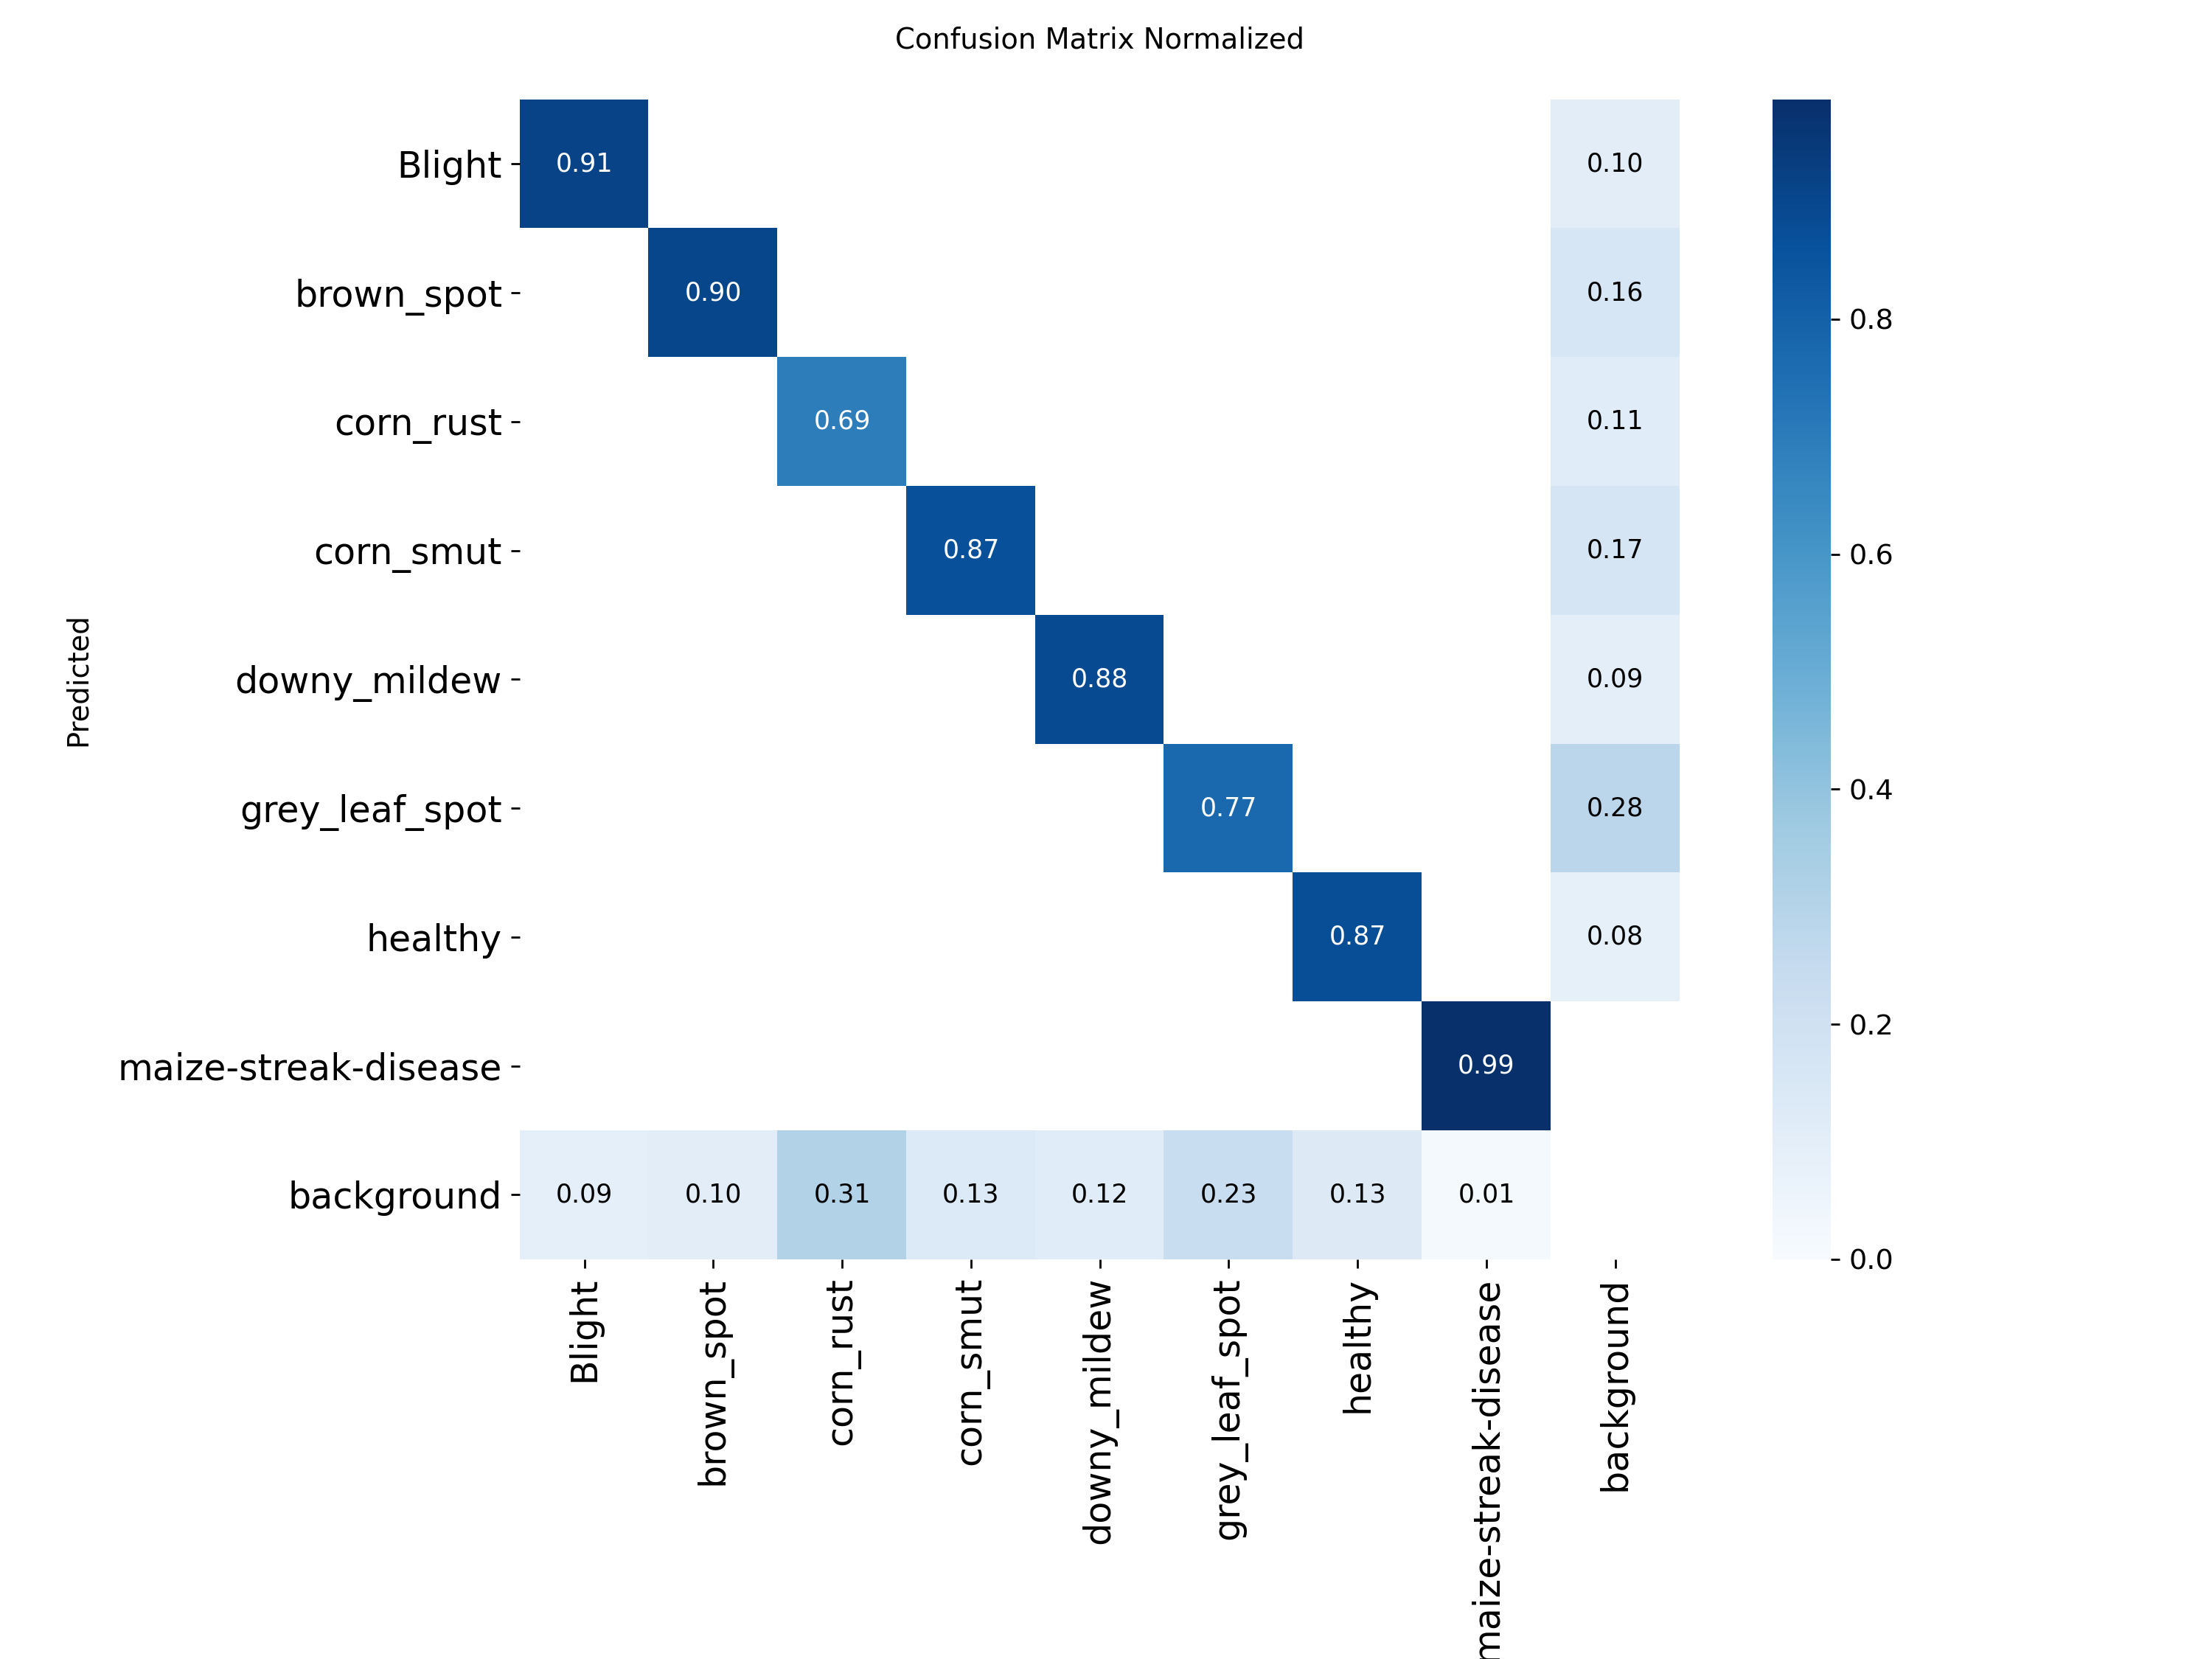

In [7]:
from IPython.display import Image, display

display(Image("/kaggle/working/runs/detect/val-3/confusion_matrix_normalized.png"))

In [8]:
"""
ERROR ANALYSIS FOR THE YOLO11n DETECTOR

Separates every prediction and every ground-truth box on the test split into
one of six outcomes, so that false positives, localization errors and missed
detections can be reported separately rather than lumped together:

  TP          correct class, IoU >= 0.5 with an unmatched ground-truth box
  Duplicate   correct class and IoU >= 0.5, but that box was already matched
  Loc         correct class, 0.1 <= IoU < 0.5            (localization error)
  Cls         wrong class, IoU >= 0.5 with some box       (classification error)
  Both        wrong class and 0.1 <= IoU < 0.5
  Bkg         IoU < 0.1 with every box                    (background false positive)
  Miss        ground-truth box with no matching detection

It also lists the images contributing the most of each error type, as
candidates for the failure examples the review asks for.
"""

from collections import defaultdict
from pathlib import Path

import numpy as np
from ultralytics import YOLO

# ----------------------------------------------------------------------------
WEIGHTS   = Path("/kaggle/working/reconstructed_best.pt")
TEST_IMG  = Path("/kaggle/working/maize-disease-detection/images/test")
TEST_LBL  = Path("/kaggle/working/maize-disease-detection/labels/test")
OUT_CSV   = Path("/kaggle/working/error_analysis.csv")

CONF      = 0.25    # same inference setting as Tables 3 and 4
IOU_TP    = 0.50    # match threshold
IOU_LOC   = 0.10    # below this a prediction is treated as background
IMGSZ     = 640
# ----------------------------------------------------------------------------

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def iou_matrix(a, b):
    """IoU between every box in a (N,4) and every box in b (M,4), xyxy."""
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    tl = np.maximum(a[:, None, :2], b[None, :, :2])
    br = np.minimum(a[:, None, 2:], b[None, :, 2:])
    wh = np.clip(br - tl, 0, None)
    inter = wh[..., 0] * wh[..., 1]
    area_a = ((a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]))[:, None]
    area_b = ((b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1]))[None, :]
    return inter / (area_a + area_b - inter + 1e-9)


model = YOLO(str(WEIGHTS))
names = model.names if isinstance(model.names, dict) else dict(enumerate(model.names))
nc = len(names)

images = sorted(p for p in TEST_IMG.iterdir() if p.suffix.lower() in IMG_EXT)
print(f"test images: {len(images)}   conf: {CONF}   IoU: {IOU_TP}")

pred_counts = defaultdict(lambda: defaultdict(int))   # [class][outcome]
gt_counts = defaultdict(lambda: defaultdict(int))     # [class][TP|Miss]
confusions = defaultdict(int)                         # (true, predicted) for Cls errors
per_image = []

for ip, img_path in enumerate(images):
    r = model.predict(str(img_path), imgsz=IMGSZ, conf=CONF,
                      device=0, verbose=False)[0]
    H, W = r.orig_shape

    # ground truth, YOLO normalised xywh -> pixel xyxy
    lbl = TEST_LBL / (img_path.stem + ".txt")
    g_cls, g_box = [], []
    if lbl.exists():
        for line in lbl.read_text().split("\n"):
            f = line.split()
            if len(f) < 5:
                continue
            c, xc, yc, w, h = int(f[0]), *map(float, f[1:5])
            g_cls.append(c)
            g_box.append([(xc - w / 2) * W, (yc - h / 2) * H,
                          (xc + w / 2) * W, (yc + h / 2) * H])
    g_cls = np.array(g_cls, dtype=int)
    g_box = np.array(g_box, dtype=float).reshape(-1, 4)

    if r.boxes is None or len(r.boxes) == 0:
        p_cls = np.zeros(0, dtype=int)
        p_box = np.zeros((0, 4))
        p_conf = np.zeros(0)
    else:
        p_cls = r.boxes.cls.cpu().numpy().astype(int)
        p_box = r.boxes.xyxy.cpu().numpy()
        p_conf = r.boxes.conf.cpu().numpy()

    ious = iou_matrix(p_box, g_box)
    gt_taken = np.zeros(len(g_cls), dtype=bool)
    img_err = defaultdict(int)

    # highest-confidence predictions claim their ground-truth box first
    for pi in np.argsort(-p_conf):
        pc = p_cls[pi]
        row = ious[pi] if ious.size else np.zeros(0)
        same = np.where(g_cls == pc)[0] if len(g_cls) else np.zeros(0, dtype=int)

        best_same, best_same_i = 0.0, -1
        if len(same):
            j = same[np.argmax(row[same])]
            best_same, best_same_i = row[j], j
        best_any = row.max() if row.size else 0.0

        if best_same >= IOU_TP:
            if not gt_taken[best_same_i]:
                gt_taken[best_same_i] = True
                outcome = "TP"
            else:
                outcome = "Duplicate"
        elif best_same >= IOU_LOC:
            outcome = "Loc"
        elif best_any >= IOU_TP:
            outcome = "Cls"
            confusions[(int(g_cls[int(np.argmax(row))]), int(pc))] += 1
        elif best_any >= IOU_LOC:
            outcome = "Both"
        else:
            outcome = "Bkg"

        pred_counts[int(pc)][outcome] += 1
        if outcome != "TP":
            img_err[outcome] += 1

    for gi, gc in enumerate(g_cls):
        gt_counts[int(gc)]["TP" if gt_taken[gi] else "Miss"] += 1
        if not gt_taken[gi]:
            img_err["Miss"] += 1

    per_image.append((img_path.name, dict(img_err)))
    if (ip + 1) % 300 == 0:
        print(f"  {ip + 1}/{len(images)}")


# ============================================================================
# PER-CLASS TABLE
# ============================================================================
print("\n" + "=" * 92)
print("ERROR BREAKDOWN BY CLASS")
print("=" * 92)
cols = ["TP", "Bkg", "Loc", "Cls", "Both", "Duplicate"]
print(f"{'class':<22}{'GT':>6}{'preds':>7}" + "".join(f"{c:>11}" for c in cols)
      + f"{'Miss':>8}")
tot = defaultdict(int)
for c in range(nc):
    gt = gt_counts[c]["TP"] + gt_counts[c]["Miss"]
    pr = sum(pred_counts[c].values())
    row = [pred_counts[c][k] for k in cols]
    miss = gt_counts[c]["Miss"]
    print(f"{names[c]:<22}{gt:>6}{pr:>7}" + "".join(f"{v:>11}" for v in row)
          + f"{miss:>8}")
    for k, v in zip(cols, row):
        tot[k] += v
    tot["Miss"] += miss
    tot["GT"] += gt
    tot["preds"] += pr
print(f"{'all':<22}{tot['GT']:>6}{tot['preds']:>7}"
      + "".join(f"{tot[c]:>11}" for c in cols) + f"{tot['Miss']:>8}")


# ============================================================================
# FALSE POSITIVES AS A SHARE OF EACH CLASS'S PREDICTIONS
# ============================================================================
print("\n" + "=" * 92)
print("FALSE POSITIVES AS A SHARE OF PREDICTIONS")
print("=" * 92)
print(f"{'class':<22}{'preds':>8}{'FP total':>10}{'% FP':>8}"
      f"{'% Bkg':>8}{'% Loc':>8}{'% Cls':>8}")
for c in range(nc):
    pr = sum(pred_counts[c].values())
    if not pr:
        continue
    fp = pr - pred_counts[c]["TP"]
    print(f"{names[c]:<22}{pr:>8}{fp:>10}{100 * fp / pr:>8.1f}"
          f"{100 * pred_counts[c]['Bkg'] / pr:>8.1f}"
          f"{100 * pred_counts[c]['Loc'] / pr:>8.1f}"
          f"{100 * pred_counts[c]['Cls'] / pr:>8.1f}")


# ============================================================================
# CLASS CONFUSIONS
# ============================================================================
if confusions:
    print("\n" + "=" * 92)
    print("CLASSIFICATION ERRORS, true -> predicted")
    print("=" * 92)
    for (t, p), n in sorted(confusions.items(), key=lambda kv: -kv[1])[:15]:
        print(f"   {names[t]:<22} -> {names[p]:<22}{n:>6}")


# ============================================================================
# CANDIDATE FAILURE IMAGES
# ============================================================================
print("\n" + "=" * 92)
print("CANDIDATE FAILURE IMAGES")
print("=" * 92)
for kind in ("Bkg", "Loc", "Cls", "Miss"):
    ranked = sorted(((d.get(kind, 0), n) for n, d in per_image), reverse=True)[:5]
    print(f"\n most {kind}:")
    for n, name in ranked:
        if n:
            print(f"   {name:<40}{n}")

import csv
with open(OUT_CSV, "w", newline="") as fh:
    w = csv.writer(fh)
    w.writerow(["image"] + cols + ["Miss"])
    for name, d in per_image:
        w.writerow([name] + [d.get(k, 0) for k in cols] + [d.get("Miss", 0)])
print(f"\nper-image breakdown saved to {OUT_CSV}")

test images: 1506   conf: 0.25   IoU: 0.5
  300/1506
  600/1506
  900/1506
  1200/1506
  1500/1506

ERROR BREAKDOWN BY CLASS
class                     GT  preds         TP        Bkg        Loc        Cls       Both  Duplicate    Miss
Blight                   428    434        375         13         29          2          1         14      53
brown_spot               347    376        296         29         38          1          1         11      51
corn_rust                503    345        292         11         27          0          0         15     211
corn_smut                395    429        318         16         80          0          0         15      77
downy_mildew             330    342        270          8         46          1          0         17      60
grey_leaf_spot           430    457        282         45        100          0          0         30     148
healthy                  438    443        374          8         32          0          0         29    

Loc    -> Corn_Gray_Spot-34-_jpg.rf.04398baee4094e7b941a909794812a19.jpg
Bkg    -> Corn_Gray_Spot-567-_jpg.rf.95b5e64ab659cbb856c9ddf8763bf9b9.jpg
Miss   -> Corn_Common_Rust-1215-_JPG_jpg.rf.8ceeca8cd6a213bdd58a50a8f94a830e.jpg

saved: /kaggle/working/figure_failure_examples.png


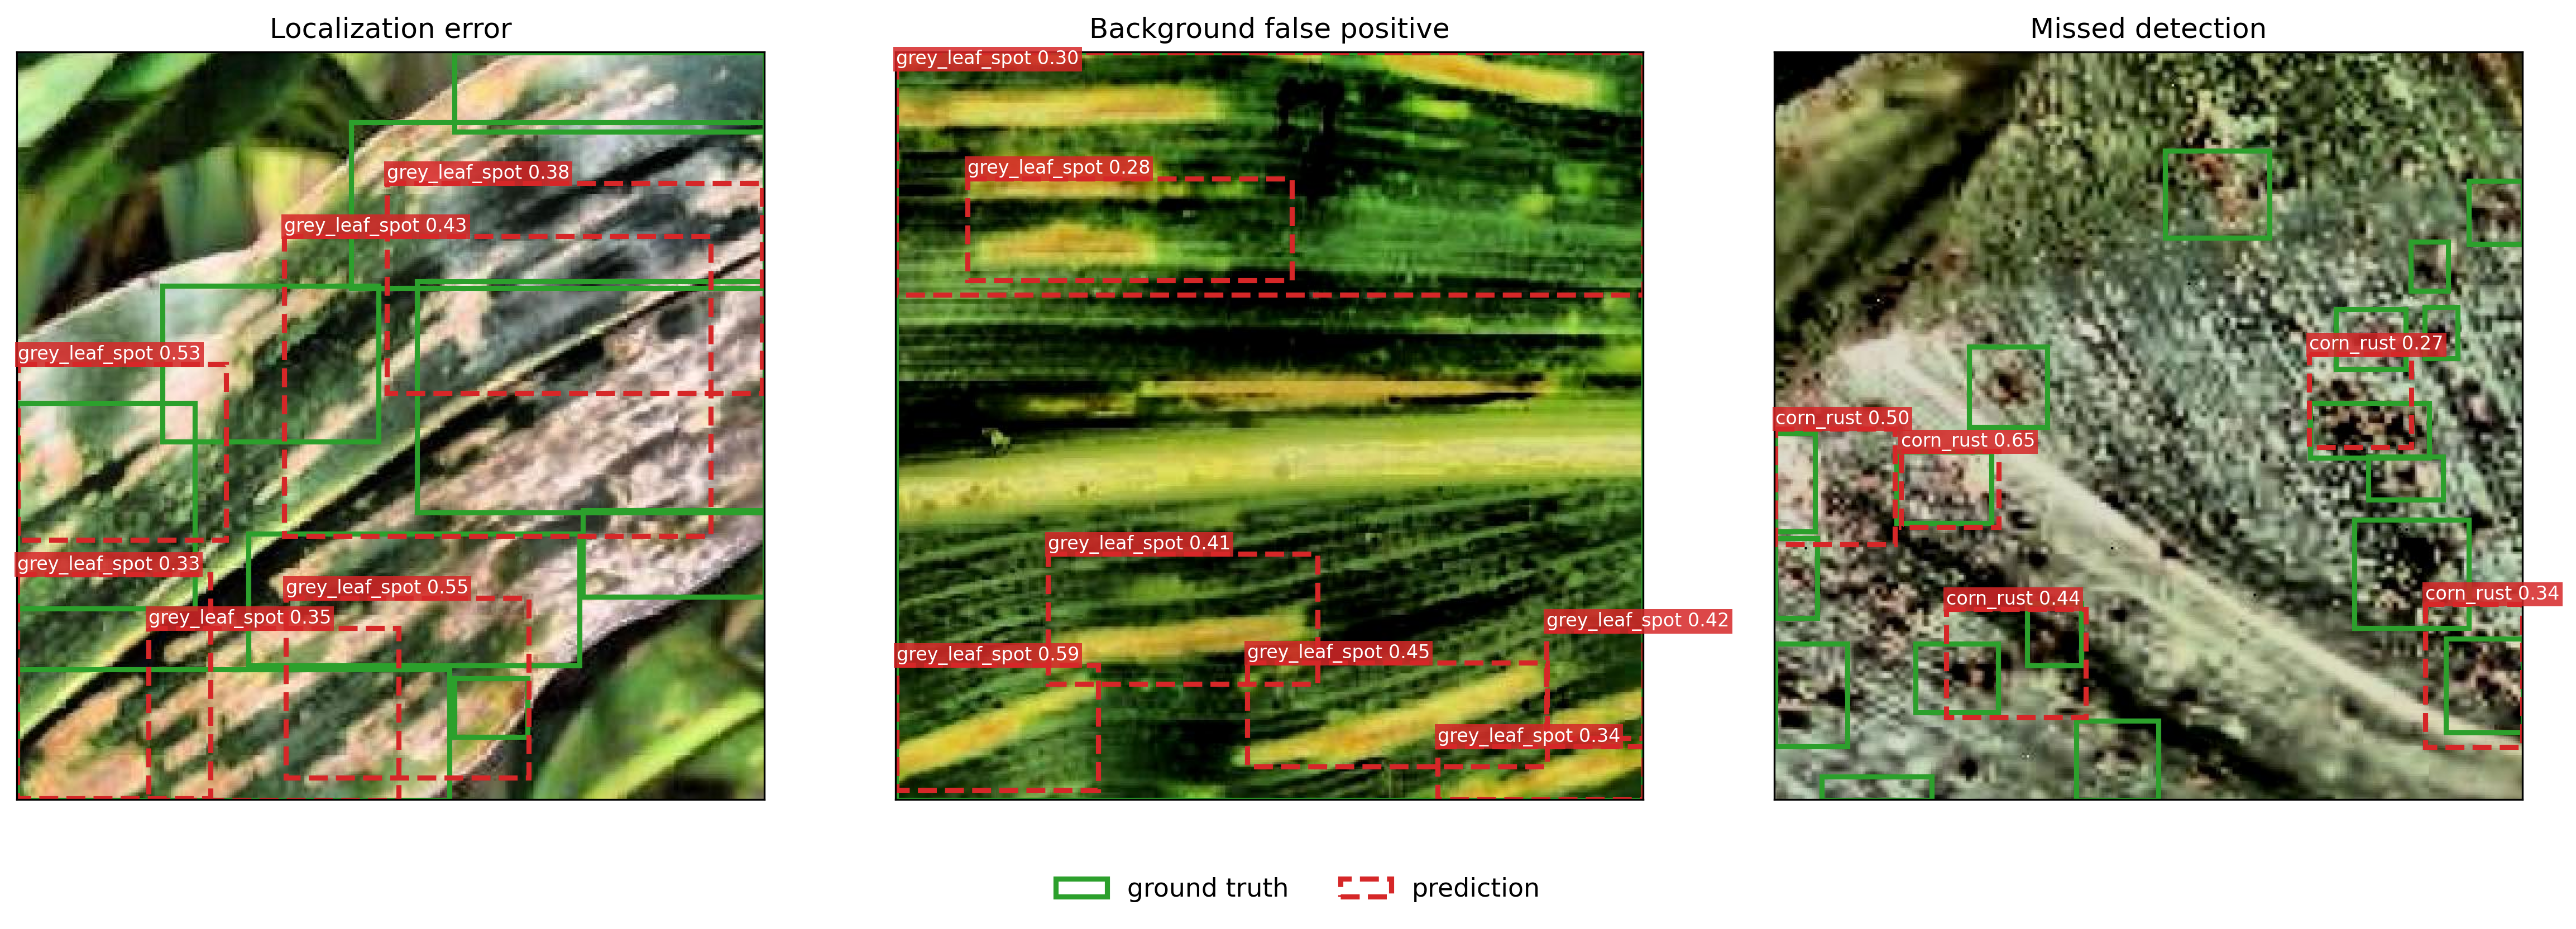

In [9]:
"""
FAILURE EXAMPLES FIGURE

Draws one representative test image for each of the three failure modes found
by error_analysis.py, with ground-truth boxes in green and predicted boxes in
red, so that the reader can see what each error type looks like:

  localization   the lesion is found but the box does not fit it (0.1 <= IoU < 0.5)
  background     a box is drawn where no annotated lesion lies
  missed         an annotated lesion receives no detection at all

Run after error_analysis.py, in the same session.
"""

from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from ultralytics import YOLO

# ----------------------------------------------------------------------------
WEIGHTS  = Path("/kaggle/working/reconstructed_best.pt")
TEST_IMG = Path("/kaggle/working/maize-disease-detection/images/test")
TEST_LBL = Path("/kaggle/working/maize-disease-detection/labels/test")
ERR_CSV  = Path("/kaggle/working/error_analysis.csv")
OUT_PNG  = Path("/kaggle/working/figure_failure_examples.png")

CONF  = 0.25
IMGSZ = 640

# Set a filename here to override the automatic choice for that panel.
OVERRIDE = {"Loc": None, "Bkg": None, "Miss": None}
# ----------------------------------------------------------------------------

PANELS = [
    ("Loc",  "Localization error"),
    ("Bkg",  "Background false positive"),
    ("Miss", "Missed detection"),
]

model = YOLO(str(WEIGHTS))
names = model.names if isinstance(model.names, dict) else dict(enumerate(model.names))

df = pd.read_csv(ERR_CSV)
chosen = {}
for key, _ in PANELS:
    if OVERRIDE.get(key):
        chosen[key] = OVERRIDE[key]
    else:
        # the image with the most errors of this type, and as few of the others
        others = [k for k, _ in PANELS if k != key]
        ranked = df.sort_values(
            by=[key] + others, ascending=[False] + [True] * len(others))
        chosen[key] = ranked.iloc[0]["image"]
    print(f"{key:<6} -> {chosen[key]}")


def load_gt(stem, W, H):
    out = []
    f = TEST_LBL / (stem + ".txt")
    if not f.exists():
        return out
    for line in f.read_text().split("\n"):
        p = line.split()
        if len(p) < 5:
            continue
        c, xc, yc, w, h = int(p[0]), *map(float, p[1:5])
        out.append((c, (xc - w / 2) * W, (yc - h / 2) * H,
                    (xc + w / 2) * W, (yc + h / 2) * H))
    return out


fig, axes = plt.subplots(1, len(PANELS), figsize=(5.2 * len(PANELS), 5.6))

for ax, (key, title) in zip(np.atleast_1d(axes), PANELS):
    fname = chosen[key]
    path = TEST_IMG / fname
    im = Image.open(path).convert("RGB")
    W, H = im.size
    ax.imshow(im)

    for c, x1, y1, x2, y2 in load_gt(path.stem, W, H):
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                       linewidth=2.2, edgecolor="#2ca02c",
                                       facecolor="none"))

    r = model.predict(str(path), imgsz=IMGSZ, conf=CONF, device=0, verbose=False)[0]
    if r.boxes is not None and len(r.boxes):
        for box, cl, cf in zip(r.boxes.xyxy.cpu().numpy(),
                               r.boxes.cls.cpu().numpy().astype(int),
                               r.boxes.conf.cpu().numpy()):
            x1, y1, x2, y2 = box
            ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                           linewidth=2.2, edgecolor="#d62728",
                                           facecolor="none", linestyle="--"))
            ax.text(x1, max(y1 - 4, 10), f"{names[cl]} {cf:.2f}",
                    color="white", fontsize=8,
                    bbox=dict(facecolor="#d62728", edgecolor="none",
                              pad=1.2, alpha=0.85))

    ax.set_title(title, fontsize=12)
    ax.set_xticks([])
    ax.set_yticks([])

handles = [
    patches.Patch(edgecolor="#2ca02c", facecolor="none", linewidth=2.2,
                  label="ground truth"),
    patches.Patch(edgecolor="#d62728", facecolor="none", linewidth=2.2,
                  linestyle="--", label="prediction"),
]
fig.legend(handles=handles, loc="lower center", ncol=2, frameon=False,
           bbox_to_anchor=(0.5, -0.01), fontsize=11)
fig.tight_layout(rect=[0, 0.045, 1, 1])
fig.savefig(OUT_PNG, dpi=300, bbox_inches="tight", facecolor="white")
print("\nsaved:", OUT_PNG)

from IPython.display import Image as IPImage, display
display(IPImage(str(OUT_PNG), width=1100))